In [1]:
from pathlib import Path

# Resolve paths whether Jupyter starts in the project root or notebooks folder.
PROJECT_DIR = next(
    directory for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / 'api' / 'api.py').is_file()
)
MODEL_DIR = PROJECT_DIR / 'models'
GRAPH_DIR = PROJECT_DIR / 'reports' / 'graphs'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, f1_score, accuracy_score
)
from xgboost import XGBClassifier
import joblib, os

np.random.seed(42)
print('✅ Libraries loaded')

✅ Libraries loaded


In [2]:
def generate_chiangmai_dataset(n_years=30, random_state=42):
    rng = np.random.default_rng(random_state)

    dates = pd.date_range(start='1995-01-01', periods=n_years*365, freq='D')
    n = len(dates)
    months = dates.month.values

    # Monsoon flag (Mayâ€“Oct)
    monsoon = ((months >= 5) & (months <= 10)).astype(float)

    # Typhoon probability (higher Augâ€“Oct)
    typhoon_prob = np.where((months >= 8) & (months <= 10), 0.015, 0.002)
    typhoon = (rng.uniform(0, 1, n) < typhoon_prob).astype(int)
    for i in range(n):
        if typhoon[i] == 1:
            duration = rng.integers(3, 8)
            typhoon[i:min(i+duration, n)] = 1

    # Rainfall
    base_rain = rng.lognormal(mean=0.5, sigma=1.8, size=n) * monsoon
    typhoon_rain = typhoon * rng.lognormal(mean=3.5, sigma=0.8, size=n)
    rainfall_24h = np.clip(base_rain + typhoon_rain, 0, 350)

    upstream_rain = np.clip(
        rainfall_24h * rng.uniform(0.6, 1.6, n) + rng.normal(0, 5, n), 0, 400
    )

    rainfall_7day = np.array([
        rainfall_24h[max(0, i-7):i].sum() for i in range(n)
    ])

    # Soil moisture â€” faster drying in dry season (fixed)
    soil_moisture = np.zeros(n)
    sm = 0.1
    for i in range(n):
        rain_in  = rainfall_24h[i] / 200.0
        evap_out = 0.006 if monsoon[i] else 0.022
        sm = np.clip(sm + rain_in - evap_out, 0.0, 1.0)
        soil_moisture[i] = sm

    # Mae Ngat reservoir
    mae_ngat = np.zeros(n)
    res = 30.0
    for i in range(n):
        inflow  = rainfall_24h[i] * 0.3 if monsoon[i] else rainfall_24h[i] * 0.05
        release = 0.4 if res > 90 else (0.2 if res > 70 else 0.05)
        res = np.clip(res + inflow * 0.1 - release, 0, 100)
        mae_ngat[i] = res

    # Ping River level â€” recalibrated coefficients (fixed)
    ping_level = (
        0.45 + 
        0.8  * soil_moisture +
        0.004  * rainfall_24h +
        0.0015 * rainfall_7day +
        0.002  * upstream_rain +
        0.008  * mae_ngat * (mae_ngat > 85) +
        0.35   * typhoon +
        rng.normal(0, 0.12, n)
    )
    ping_level = np.clip(ping_level, 0.3, 6.0)

    flood = (ping_level >= 3.7).astype(int)

    df = pd.DataFrame({
        'date':             dates,
        'month':            months,
        'rainfall_24h':     np.round(rainfall_24h, 1),
        'rainfall_7day':    np.round(rainfall_7day, 1),
        'upstream_rain':    np.round(upstream_rain, 1),
        'ping_level':       np.round(ping_level, 2),
        'mae_ngat_storage': np.round(mae_ngat, 1),
        'soil_moisture':    np.round(soil_moisture, 3),
        'typhoon_active':   typhoon,
        'flood':            flood
    })
    return df

df = generate_chiangmai_dataset(n_years=30)
print(f'Dataset:    {len(df):,} daily records  ({df.date.min().date()} â†’ {df.date.max().date()})')
print(f'Flood days: {df.flood.sum():,} ({df.flood.mean():.1%} of all days)')
print(f'Max Ping:   {df.ping_level.max():.2f} m')
df.head(10)

Dataset:    10,950 daily records  (1995-01-01 â†’ 2024-12-23)
Flood days: 848 (7.7% of all days)
Max Ping:   5.68 m


,date,month,rainfall_24h,rainfall_7day,upstream_rain,ping_level,mae_ngat_storage,soil_moisture,typhoon_active,flood
0,1995-01-01,1,0.0,0.0,0.6,0.43,30.0,0.078,0,0
1,1995-01-02,1,0.0,0.0,0.0,0.62,29.9,0.056,0,0
2,1995-01-03,1,0.0,0.0,3.5,0.45,29.8,0.034,0,0
3,1995-01-04,1,0.0,0.0,3.6,0.48,29.8,0.012,0,0
4,1995-01-05,1,0.0,0.0,0.0,0.50,29.7,0.000,0,0
5,1995-01-06,1,0.0,0.0,8.4,0.39,29.7,0.000,0,0
6,1995-01-07,1,0.0,0.0,2.3,0.30,29.6,0.000,0,0
7,1995-01-08,1,0.0,0.0,1.6,0.58,29.6,0.000,0,0
8,1995-01-09,1,0.0,0.0,3.4,0.47,29.5,0.000,0,0
9,1995-01-10,1,0.0,0.0,0.0,0.30,29.5,0.000,0,0


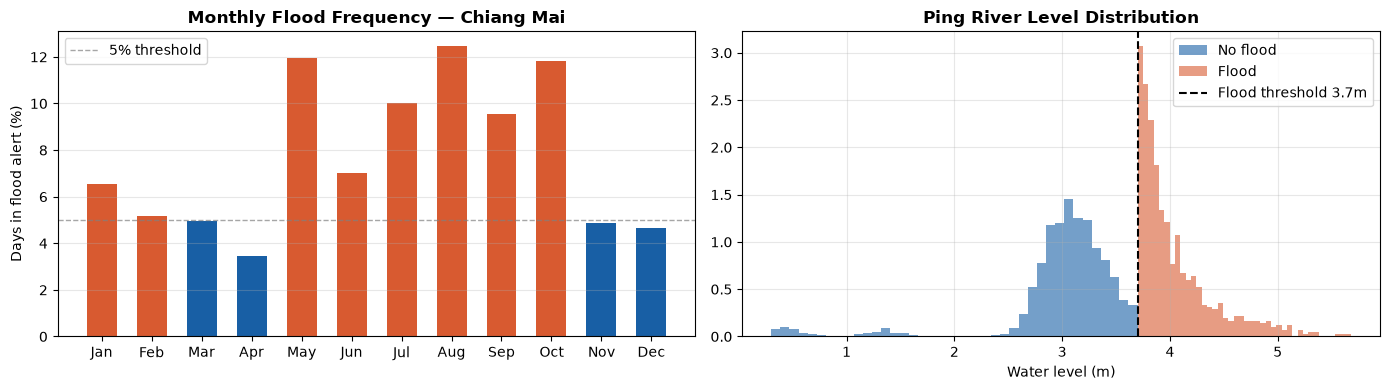

In [5]:
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly_flood = df.groupby('month')['flood'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Monthly flood rate
colors = ['#D85A30' if v > 5 else '#185FA5' for v in monthly_flood.values]
axes[0].bar(month_names, monthly_flood.values, color=colors, width=0.6)
axes[0].axhline(5, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='5% threshold')
axes[0].set_title('Monthly Flood Frequency — Chiang Mai', fontweight='bold')
axes[0].set_ylabel('Days in flood alert (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Ping River level distribution
axes[1].hist(df[df.flood==0]['ping_level'], bins=40, alpha=0.6, color='#185FA5', label='No flood', density=True)
axes[1].hist(df[df.flood==1]['ping_level'], bins=40, alpha=0.6, color='#D85A30', label='Flood', density=True)
axes[1].axvline(3.7, color='black', linestyle='--', linewidth=1.5, label='Flood threshold 3.7m')
axes[1].set_title('Ping River Level Distribution', fontweight='bold')
axes[1].set_xlabel('Water level (m)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(GRAPH_DIR / 'chiangmai_eda.png', dpi=150, bbox_inches='tight')
plt.show()

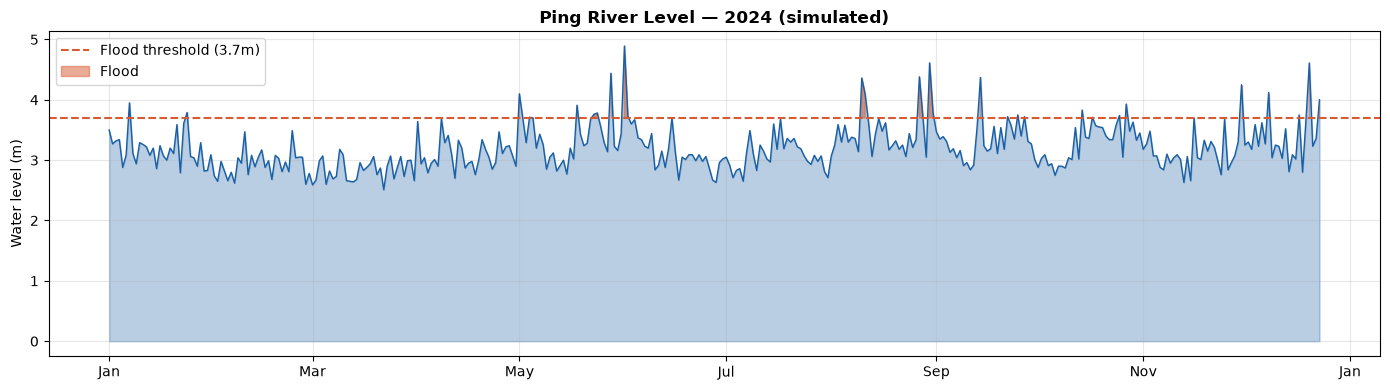

In [6]:
# Time series: Ping River level for most recent year
recent = df[df.date.dt.year == df.date.dt.year.max()].copy()

fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(recent.date, recent.ping_level, alpha=0.3, color='#185FA5')
ax.plot(recent.date, recent.ping_level, color='#185FA5', linewidth=1)
ax.axhline(3.7, color='#D85A30', linestyle='--', linewidth=1.5, label='Flood threshold (3.7m)')
ax.fill_between(recent.date, 3.7, recent.ping_level.where(recent.ping_level >= 3.7),
                color='#D85A30', alpha=0.5, label='Flood')
ax.set_title(f'Ping River Level — {recent.date.dt.year.max()} (simulated)', fontweight='bold')
ax.set_ylabel('Water level (m)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(GRAPH_DIR / 'ping_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

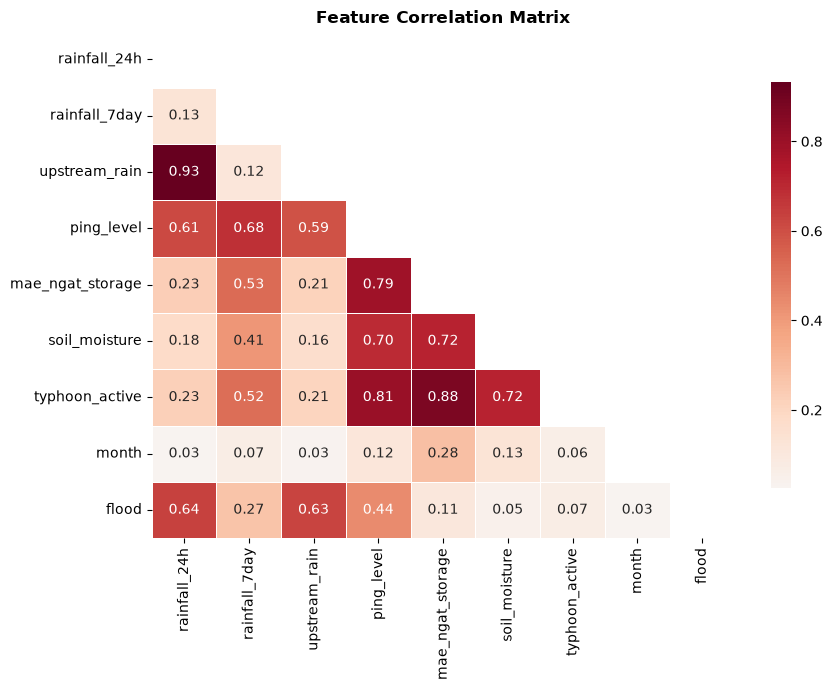

In [7]:
# Correlation heatmap
feat_cols = ['rainfall_24h','rainfall_7day','upstream_rain','ping_level',
             'mae_ngat_storage','soil_moisture','typhoon_active','month','flood']

fig, ax = plt.subplots(figsize=(9, 7))
corr = df[feat_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Matrix', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(GRAPH_DIR / 'correlation.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Feature engineering: add sine/cosine of month for cyclical encoding
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

FEATURES = [
    'rainfall_24h',
    'rainfall_7day',
    'upstream_rain',
    'ping_level',
    'mae_ngat_storage',
    'soil_moisture',
    'typhoon_active',
    'month_sin',
    'month_cos'
]

X = df[FEATURES]
y = df['flood']

# Time-aware split: train on earlier years, test on recent years
split_year = df.date.dt.year.max() - 5
train_mask = df.date.dt.year <= split_year
X_train, y_train = X[train_mask], y[train_mask]
X_test,  y_test  = X[~train_mask], y[~train_mask]

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Train: {len(X_train):,} days (up to {split_year})')
print(f'Test:  {len(X_test):,} days  ({split_year+1}–{df.date.dt.year.max()})')
print(f'Train flood rate: {y_train.mean():.1%}   Test flood rate: {y_test.mean():.1%}')

Train: 9,131 days (up to 2019)
Test:  1,819 days  (2020–2024)
Train flood rate: 7.7%   Test flood rate: 8.0%


In [9]:
models = {
    'Logistic Regression': (LogisticRegression(C=0.5, max_iter=1000, random_state=42), True),
    'Random Forest':       (RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1), False),
    'Gradient Boosting':   (GradientBoostingClassifier(n_estimators=300, learning_rate=0.04, max_depth=5, random_state=42), False),
    'Neural Network':      (MLPClassifier(hidden_layer_sizes=(128, 64, 32), max_iter=500, random_state=42, early_stopping=True), True),
}

results = {}

for name, (model, use_scale) in models.items():
    Xtr = X_train_sc if use_scale else X_train
    Xte = X_test_sc  if use_scale else X_test

    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]

    results[name] = {
        'model': model, 'use_scale': use_scale,
        'y_pred': y_pred, 'y_prob': y_prob,
        'accuracy': accuracy_score(y_test, y_pred),
        'f1':       f1_score(y_test, y_pred),
        'roc_auc':  roc_auc_score(y_test, y_prob),
    }
    print(f'{name:<25} Acc={results[name]["accuracy"]:.3f}  '
          f'F1={results[name]["f1"]:.3f}  ROC-AUC={results[name]["roc_auc"]:.3f}')

Logistic Regression       Acc=0.987  F1=0.914  ROC-AUC=0.998
Random Forest             Acc=0.996  F1=0.976  ROC-AUC=1.000
Gradient Boosting         Acc=0.997  F1=0.979  ROC-AUC=1.000
Neural Network            Acc=0.993  F1=0.955  ROC-AUC=0.999


In [12]:
best_name = max(results, key=lambda k: results[k]['roc_auc'])
best = results[best_name]
print(f"Best model: {best_name}  ROC-AUC={best['roc_auc']:.4f}")

Best model: Gradient Boosting  ROC-AUC=0.9999


In [14]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(best['model'], MODEL_DIR / 'chiangmai_flood_model.pkl')
joblib.dump(scaler, MODEL_DIR / 'scaler.pkl')
pd.Series(FEATURES).to_csv(MODEL_DIR / 'features.csv', index=False, header=False)

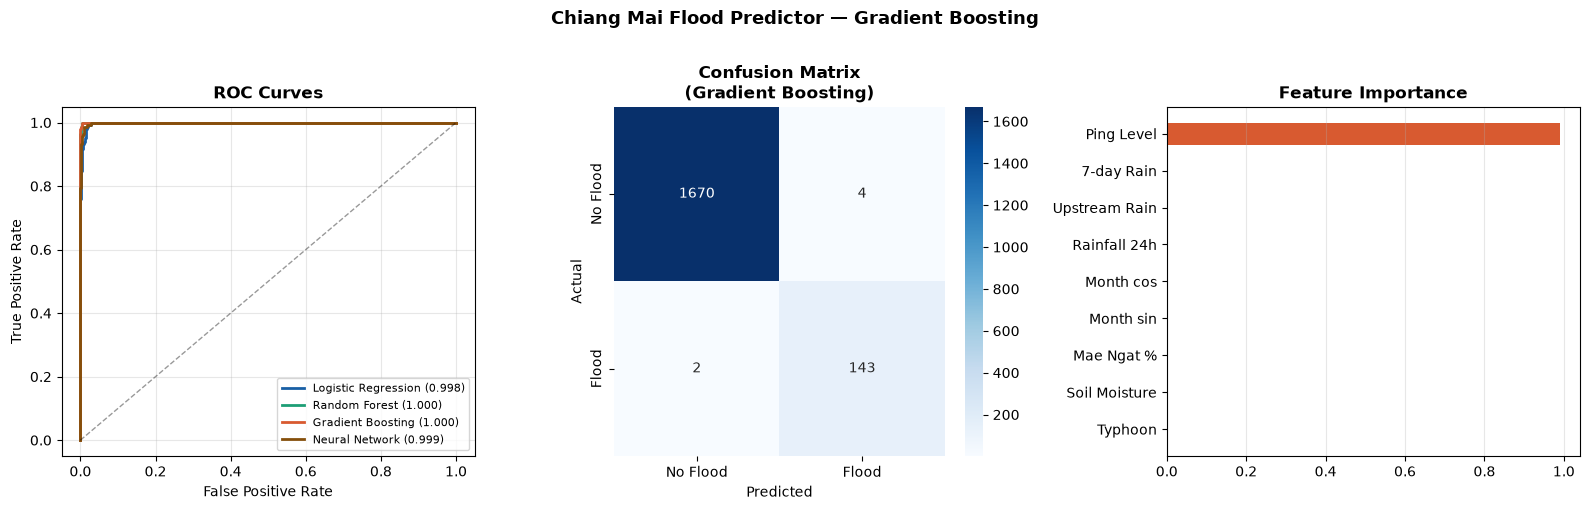

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
palette = ['#185FA5','#1D9E75','#D85A30','#854F0B']

# ROC curves
ax = axes[0]
for (name, res), color in zip(results.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    ax.plot(fpr, tpr, label=f"{name} ({res['roc_auc']:.3f})", color=color, lw=2)
ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.4)
ax.set_title('ROC Curves', fontweight='bold')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Confusion matrix
ax = axes[1]
cm = confusion_matrix(y_test, best['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['No Flood','Flood'], yticklabels=['No Flood','Flood'])
ax.set_title(f'Confusion Matrix\n({best_name})', fontweight='bold')
ax.set_ylabel('Actual')
ax.set_xlabel('Predicted')

# Feature importance
ax = axes[2]
m = best['model']
if hasattr(m, 'feature_importances_'):
    imp = m.feature_importances_
elif hasattr(m, 'coef_'):
    imp = np.abs(m.coef_[0])
else:
    imp = np.ones(len(FEATURES))

feat_labels = ['Rainfall 24h','7-day Rain','Upstream Rain','Ping Level',
               'Mae Ngat %','Soil Moisture','Typhoon','Month sin','Month cos']
imp_df = pd.DataFrame({'Feature': feat_labels, 'Importance': imp}).sort_values('Importance')
bar_colors = ['#D85A30' if i >= len(feat_labels)-3 else '#185FA5' for i in range(len(feat_labels))]
ax.barh(imp_df['Feature'], imp_df['Importance'], color=bar_colors, height=0.6)
ax.set_title('Feature Importance', fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

plt.suptitle(f'Chiang Mai Flood Predictor — {best_name}', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(GRAPH_DIR / 'model_results.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
def predict_chiangmai_flood(conditions: dict) -> dict:
    """
    Predict flood probability for Chiang Mai given current conditions.

    Parameters
    ----------
    conditions : dict with keys:
        rainfall_24h     : float  — 24-hour rainfall in mm
        rainfall_7day    : float  — 7-day cumulative rainfall in mm
        upstream_rain    : float  — upstream (Mae Rim/Chom Thong) rainfall in mm
        ping_level       : float  — current Ping River level in meters
        mae_ngat_storage : float  — Mae Ngat reservoir storage in %
        soil_moisture    : float  — soil moisture index 0–1
        typhoon_active   : int    — 1 if tropical cyclone active nearby
        month            : int    — month (1–12)

    Returns
    -------
    dict: probability, risk level, and alert message
    """
    import numpy as np

    month = conditions.get('month', 8)
    conditions['month_sin'] = np.sin(2 * np.pi * month / 12)
    conditions['month_cos'] = np.cos(2 * np.pi * month / 12)

    X_in = pd.DataFrame([conditions])[FEATURES]
    X_sc  = scaler.transform(X_in) if best['use_scale'] else X_in
    prob  = best['model'].predict_proba(X_sc)[:, 1][0]

    if prob < 0.20:
        risk = 'Low';       alert = '✅ Normal conditions — no action needed.'
    elif prob < 0.45:
        risk = 'Moderate';  alert = '⚠️ Monitor Ping River levels. Prepare sandbags in low-lying areas near Nawarat Bridge.'
    elif prob < 0.70:
        risk = 'High';      alert = '🚨 Flood likely. Alert authorities. Move valuables from riverside areas (Warorot, Muang Mai markets).'
    else:
        risk = 'Extreme';   alert = '🔴 Imminent flood. Evacuate Riverside / Nimmanhaemin low-lying zones. Contact Chiang Mai DPM: 053-112-000.'

    return {'probability': round(prob, 4), 'risk_level': risk, 'alert': alert}


# --- Scenario 1: October 2024-like conditions ---
oct2024 = {
    'rainfall_24h': 210,
    'rainfall_7day': 520,
    'upstream_rain': 280,
    'ping_level': 4.2,       # rising fast
    'mae_ngat_storage': 97,  # near capacity → forced release
    'soil_moisture': 0.95,
    'typhoon_active': 1,     # Typhoon Yagi remnant
    'month': 10
}

# --- Scenario 2: Normal dry season (February) ---
dry_feb = {
    'rainfall_24h': 0,
    'rainfall_7day': 2,
    'upstream_rain': 1,
    'ping_level': 0.9,
    'mae_ngat_storage': 45,
    'soil_moisture': 0.12,
    'typhoon_active': 0,
    'month': 2
}

# --- Scenario 3: Early monsoon (June, moderate rain) ---
jun_moderate = {
    'rainfall_24h': 65,
    'rainfall_7day': 180,
    'upstream_rain': 80,
    'ping_level': 2.8,
    'mae_ngat_storage': 72,
    'soil_moisture': 0.60,
    'typhoon_active': 0,
    'month': 6
}

print('=== Chiang Mai Flood Prediction Scenarios ===\n')
for name, cond in [('October 2024-like (Typhoon + Heavy Rain)', oct2024),
                    ('February Dry Season', dry_feb),
                    ('June Early Monsoon', jun_moderate)]:
    r = predict_chiangmai_flood(cond)
    print(f'Scenario: {name}')
    print(f'  Probability: {r["probability"]:.1%}   Risk: {r["risk_level"]}')
    print(f'  {r["alert"]}')
    print()

=== Chiang Mai Flood Prediction Scenarios ===

Scenario: October 2024-like (Typhoon + Heavy Rain)
  Probability: 100.0%   Risk: Extreme
  🔴 Imminent flood. Evacuate Riverside / Nimmanhaemin low-lying zones. Contact Chiang Mai DPM: 053-112-000.

Scenario: February Dry Season
  Probability: 0.0%   Risk: Low
  ✅ Normal conditions — no action needed.

Scenario: June Early Monsoon
  Probability: 0.0%   Risk: Low
  ✅ Normal conditions — no action needed.

